# Lab 1-02：Hugging Face——開放模型從哪裡來、怎麼用

**目標**：認識 Hugging Face 這個平台和它的幾個函式庫：在 Hub 上查模型、只下載需要的檔案、看懂本機快取，
再用 `transformers` 的 tokenizer／model／`pipeline` 跟本機模型對話，用 `datasets` 載入資料集。
後面 Lab 1-03 打開模型內部、模組 6 用 LoRA 微調，都建立在這一本上。

**你會學到**
- Hub 上有什麼：模型、資料集、Spaces；model card 和授權怎麼看；gated 模型和 `HF_TOKEN`
- 用 `huggingface_hub` 查模型資訊、列檔案、只下載 `config.json` 看架構
- 下載的東西存在哪、佔多少空間（`HF_HOME`、`scan_cache_dir`）
- `transformers` 三件套：tokenizer、model、`pipeline`；`apply_chat_template` 做了什麼
- `datasets` 的載入、`map`、切分；`safetensors` 為什麼取代 `.bin`
- 本地跑 HF 模型和跑 Ollama（GGUF）各適合什麼時候

**前置**：先讀 `00_concepts.md` 第 7 節（Hugging Face 生態系）。會用到 `Qwen/Qwen2.5-0.5B-Instruct`（約 1GB，已下載就不會重抓）和 `fancyzhx/ag_news` 資料集（約 20MB）。
查 Hub 資訊需要網路；不需要帳號。

**對應投影片**：「開放權重與商業 API」「依顯存選本地模型」「預訓練到對話模型」

![from_pretrained 的流程：先查本機快取，沒有才從 Hub 下載到 blobs，再由 snapshots 用連結指過去](images/hf_cache_flow.jpg)

*圖：`from_pretrained("Qwen/...")` 先看本機快取有沒有，有就直接讀（朱紅那條路，不用網路）；沒有才去 Hub 下載。
真正的檔案存在 `blobs/`，`snapshots/<版本>/` 底下是指過去的連結，所以不同版本共用相同的檔案不會重複佔空間。*

## Step 1：Hub 上的一個模型長什麼樣

Hugging Face 一開始（2016）是做聊天機器人 App 的公司；2018 年他們把 Google 的 BERT 移植到 PyTorch 並開源，
這個專案後來長成 `transformers`，公司也轉型成「開放模型的 GitHub」。今天 Hub 上有上百萬個模型、資料集和 Spaces（線上 demo）。

每個模型是一個 git repo，名字是「組織/模型」。先用 `model_info` 查一個我們之後會用的模型：

In [1]:
from huggingface_hub import model_info

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
info = model_info(MODEL, files_metadata=True)

print("模型：", info.id)
print("任務：", info.pipeline_tag, "｜函式庫：", info.library_name)
print("授權：", info.card_data.get("license"), "｜gated：", info.gated)
print("下載數（近 30 天）：", f"{info.downloads:,}", "｜讚：", info.likes)
print("基底模型：", info.card_data.get("base_model"))
print("標籤：", info.tags[:8])

模型： Qwen/Qwen2.5-0.5B-Instruct
任務： text-generation ｜函式庫： transformers
授權： apache-2.0 ｜gated： False
下載數（近 30 天）： 4,098,275 ｜讚： 752
基底模型： Qwen/Qwen2.5-0.5B
標籤： ['transformers', 'safetensors', 'qwen2', 'text-generation', 'chat', 'conversational', 'en', 'arxiv:2407.10671']


幾個欄位的意思：
- `pipeline_tag`：這個模型做什麼任務（`text-generation` 就是生成文字）。
- `license`：能不能商用。Qwen2.5 是 `apache-2.0`，商用沒問題；有些模型是自訂授權，用之前要讀。
- `base_model`：這個 Instruct 版是從哪個基礎模型再訓練來的。Lab 1-03 會兩個都用到。

## Step 2：Model card——模型的說明書

repo 裡的 `README.md` 就是 model card：訓練資料、能力、限制、建議的使用方式都寫在這裡。
上面那些授權、基底模型欄位，其實就是讀它開頭的 YAML。

In [2]:
from huggingface_hub import ModelCard

card = ModelCard.load(MODEL)
print("YAML 中繼資料：", card.data.to_dict())
print("-" * 40)
print(card.text.strip()[:600])

YAML 中繼資料： {'base_model': 'Qwen/Qwen2.5-0.5B', 'language': ['en'], 'library_name': 'transformers', 'license': 'apache-2.0', 'license_link': 'https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct/blob/main/LICENSE', 'pipeline_tag': 'text-generation', 'tags': ['chat']}
----------------------------------------
# Qwen2.5-0.5B-Instruct

## Introduction

Qwen2.5 is the latest series of Qwen large language models. For Qwen2.5, we release a number of base language models and instruction-tuned language models ranging from 0.5 to 72 billion parameters. Qwen2.5 brings the following improvements upon Qwen2:

- Significantly **more knowledge** and has greatly improved capabilities in **coding** and **mathematics**, thanks to our specialized expert models in these domains.
- Significant improvements in **instruction following**, **generating long texts** (over 8K tokens), **understanding structured data** (e.g


## Step 3：repo 裡有哪些檔案

一個模型 repo 就是幾個檔案：權重、架構設定、tokenizer。真正大的只有權重。

In [3]:
for f in sorted(info.siblings, key=lambda s: -(s.size or 0)):
    print(f"{f.rfilename:<26}{f.size / 1e6:>10.1f} MB")

model.safetensors              988.1 MB
tokenizer.json                   7.0 MB
vocab.json                       2.8 MB
merges.txt                       1.7 MB
LICENSE                          0.0 MB
tokenizer_config.json            0.0 MB
README.md                        0.0 MB
.gitattributes                   0.0 MB
config.json                      0.0 MB
generation_config.json           0.0 MB


| 檔案 | 內容 | 誰會讀它 |
|---|---|---|
| `model.safetensors` | 權重（每個矩陣的數字） | `AutoModel...` |
| `config.json` | 架構：幾層、多寬、幾個頭 | `AutoConfig`、`AutoModel...` |
| `tokenizer.json`、`vocab.json`、`merges.txt` | 詞表和 BPE 合併規則（Lab 1-01） | `AutoTokenizer` |
| `tokenizer_config.json` | 特殊 token 和 chat template | `apply_chat_template` |
| `generation_config.json` | 預設的溫度、top-p、停止 token | `generate()` |

## Step 4：只下載 `config.json`，不用抓整個模型就能看架構

`hf_hub_download` 一次只下載一個檔案。想知道 7B 模型有多大、要多少顯存，不必先下載 15GB：
抓同系列四個尺寸的 `config.json`（每個不到 1KB）比一比。

In [4]:
import json

from huggingface_hub import hf_hub_download

rows = []
for size in ["0.5B", "1.5B", "3B", "7B"]:
    path = hf_hub_download(f"Qwen/Qwen2.5-{size}-Instruct", "config.json")
    cfg = json.load(open(path))
    rows.append((size, cfg["num_hidden_layers"], cfg["hidden_size"], cfg["num_attention_heads"],
                 cfg["num_key_value_heads"], cfg["vocab_size"], cfg["max_position_embeddings"]))

print(f"{'尺寸':<6}{'層數':>5}{'向量寬':>8}{'Q 頭':>6}{'KV 頭':>6}{'詞表':>9}{'位置上限':>9}")
for r in rows:
    print(f"{r[0]:<6}{r[1]:>5}{r[2]:>8}{r[3]:>6}{r[4]:>6}{r[5]:>9}{r[6]:>9}")
print("\n檔案存在：", path)

尺寸       層數     向量寬   Q 頭  KV 頭       詞表     位置上限
0.5B     24     896    14     2   151936    32768
1.5B     28    1536    12     2   151936    32768
3B       36    2048    16     2   151936    32768
7B       28    3584    28     4   152064    32768

檔案存在： /home/os-sunnie.gd.weng/.cache/huggingface/hub/models--Qwen--Qwen2.5-7B-Instruct/snapshots/a09a35458c702b33eeacc393d103063234e8bc28/config.json


尺寸變大，主要是「更多層」和「向量更寬」；詞表大小幾乎不變。
KV 頭比 Q 頭少，是 GQA（多個 Q 頭共用一組 K、V），目的是省推論時的記憶體。

參數量也可以不下載權重就查到：safetensors 檔案開頭有一段小小的索引，`get_safetensors_metadata` 只讀那一段。

In [5]:
from huggingface_hub import get_safetensors_metadata

for size in ["0.5B", "1.5B", "3B", "7B"]:
    meta = get_safetensors_metadata(f"Qwen/Qwen2.5-{size}-Instruct")
    n = sum(meta.parameter_count.values())
    print(f"{size:<5} {n / 1e9:5.2f}B 參數  bf16 權重約 {n * 2 / 1e9:5.1f} GB  資料型別：{list(meta.parameter_count)}")

0.5B   0.49B 參數  bf16 權重約   1.0 GB  資料型別：['BF16']
1.5B   1.54B 參數  bf16 權重約   3.1 GB  資料型別：['BF16']
3B     3.09B 參數  bf16 權重約   6.2 GB  資料型別：['BF16']
7B     7.62B 參數  bf16 權重約  15.2 GB  資料型別：['BF16']


顯存的粗估：參數量 × 每個參數的 byte 數（bf16 是 2）。7B 光權重就要 15GB，再加上推論時的 KV cache，
一張 16GB 的卡就很緊了。這也是為什麼本地常用 4-bit 量化的 GGUF（Step 13）。

## Step 5：gated 模型與 `HF_TOKEN`

有些模型（例如 Meta 的 Llama）要先在網頁上同意授權才能下載，這叫 **gated**。
沒登入時去抓，會得到 `GatedRepoError`：

In [6]:
from huggingface_hub import get_token
from huggingface_hub.errors import GatedRepoError

GATED = "meta-llama/Llama-3.2-1B"
print("gated 狀態：", model_info(GATED).gated)
print("本機有沒有 HF token：", "有" if get_token() else "沒有")
try:
    hf_hub_download(GATED, "config.json")
    print("下載成功：你已登入並同意過授權")
except GatedRepoError as exc:
    print(type(exc).__name__, "→", str(exc).splitlines()[0][:80])

gated 狀態： manual
本機有沒有 HF token： 沒有
GatedRepoError → 401 Client Error. (Request ID: Root=1-6afe769f-1a5a73f208577ec9668b761e;52e11368


要下載 gated 模型：
1. 在模型頁面按同意授權（有的是自動通過，有的要等人工審核）。
2. 在 Hugging Face 帳號設定建立一把 Access Token（read 權限就夠）。
3. 放進 `.env` 的 `HF_TOKEN=...`，或在終端機跑 `hf auth login`。`huggingface_hub` 會自動讀到。

金鑰一樣不寫進程式碼、不 commit。本課用的 Qwen 都不是 gated，不需要 token。

## Step 6：下載的東西存在哪

所有函式庫共用同一個快取資料夾。預設是 `~/.cache/huggingface`，設環境變數 `HF_HOME` 可以搬到別的磁碟（例如空間比較大的那顆）。

In [7]:
import os

from huggingface_hub import constants

print("HF_HOME：", os.getenv("HF_HOME", "（沒設，用預設值）"))
print("模型與資料集快取：", constants.HF_HUB_CACHE)

# 打開剛才那個模型的資料夾，就是開頭那張圖的結構
from pathlib import Path

repo_dir = Path(constants.HF_HUB_CACHE) / ("models--" + MODEL.replace("/", "--"))
print("refs/main 指向版本：", (repo_dir / "refs" / "main").read_text()[:12], "…")
blobs = list((repo_dir / "blobs").iterdir())
print(f"blobs/：{len(blobs)} 個實體檔，合計 {sum(b.stat().st_size for b in blobs) / 1e9:.2f} GB（檔名是內容的雜湊）")
snapshot = next((repo_dir / "snapshots").iterdir())
print(f"snapshots/{snapshot.name[:12]}…/")
for p in sorted(snapshot.iterdir()):
    print(f"   {p.name:<24} -> blobs/{os.readlink(p).split('/')[-1][:12]}…")

HF_HOME： （沒設，用預設值）
模型與資料集快取： /home/os-sunnie.gd.weng/.cache/huggingface/hub
refs/main 指向版本： 7ae557604adf …
blobs/：8 個實體檔，合計 1.00 GB（檔名是內容的雜湊）
snapshots/7ae557604adf…/
   README.md                -> blobs/4b8373851d09…
   config.json              -> blobs/0dbb16121362…
   generation_config.json   -> blobs/dfc11073787d…
   merges.txt               -> blobs/20024bfe7c83…
   model.safetensors        -> blobs/fdf756fa7fcb…
   tokenizer.json           -> blobs/443909a61d42…
   tokenizer_config.json    -> blobs/07bfe0640cb5…
   vocab.json               -> blobs/4783fe10ac3a…


## Step 7：快取佔了多少空間

模型一個動輒好幾 GB，磁碟很快就滿。`scan_cache_dir` 會列出每個 repo 的大小，
終端機的 `hf cache ls` 也看得到；不要的用 `hf cache rm model/<repo>` 刪掉，不要直接 `rm -rf` 半個資料夾。

In [8]:
from huggingface_hub import scan_cache_dir

cache = scan_cache_dir()
repos = sorted(cache.repos, key=lambda r: -r.size_on_disk)
print(f"快取總共 {cache.size_on_disk / 1e9:.1f} GB，{len(repos)} 個 repo")
for r in repos[:8]:
    print(f"{r.repo_type:<8}{r.repo_id:<45}{r.size_on_disk / 1e9:>6.2f} GB")

快取總共 9.8 GB，33 個 repo
model   FunAudioLLM/Fun-ASR-Nano-2512                  1.99 GB
model   Qwen/Qwen2.5-0.5B-Instruct                     1.00 GB
model   Qwen/Qwen2.5-0.5B                              1.00 GB
dataset microsoft/cats_vs_dogs                         0.72 GB
model   openai/clip-vit-base-patch32                   0.61 GB
model   XXXXRT/GPT-SoVITS-Pretrained                   0.59 GB
model   cross-encoder/mmarco-mMiniLMv2-L12-H384-v1     0.49 GB
model   Systran/faster-whisper-small.en                0.49 GB


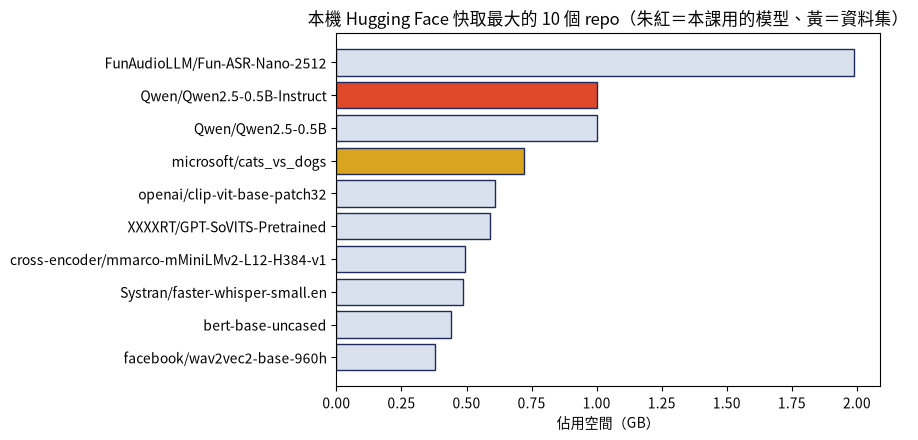

In [9]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

top = repos[:10][::-1]
colors = ["#e0482c" if r.repo_id == MODEL else "#d9e1ee" if r.repo_type == "model" else "#d9a520" for r in top]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh([r.repo_id for r in top], [r.size_on_disk / 1e9 for r in top], color=colors, edgecolor="#1f2a5c")
ax.set_xlabel("佔用空間（GB）")
ax.set_title("本機 Hugging Face 快取最大的 10 個 repo（朱紅＝本課用的模型、黃＝資料集）")
plt.tight_layout()
plt.show()

你的圖會跟這裡不一樣：它反映的是你自己的電腦下載過什麼。

## Step 8：`transformers` 之一——tokenizer

`transformers` 用 `Auto` 開頭的類別依 `config.json` 自動挑對的實作，你只要給 repo 名字。
tokenizer 把文字變 token id（Lab 1-01 看過）；對話模型還多一件事：`apply_chat_template` 把 `messages` 攤平成模型訓練時看過的格式。

In [10]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(MODEL)
messages = [
    {"role": "system", "content": "你是海賊王百科，用繁體中文、一句話回答。"},
    {"role": "user", "content": "草帽海賊團的船長是誰？"},
]
text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
print(text)
print("token 數：", len(tok(text).input_ids))

<|im_start|>system
你是海賊王百科，用繁體中文、一句話回答。<|im_end|>
<|im_start|>user
草帽海賊團的船長是誰？<|im_end|>
<|im_start|>assistant

token 數： 41


`<|im_start|>`、`<|im_end|>` 是特殊 token，標出每一段是誰說的。`add_generation_prompt=True` 在最後補上
`<|im_start|>assistant`，等於告訴模型「輪到你了」。每家模型的格式不同，所以一定要用模型自己的 tokenizer 套。

## Step 9：`transformers` 之二——model

`AutoModelForCausalLM` 是「猜下一個 token」的模型（causal LM）。`dtype="auto"` 照 `config.json` 用 bf16，
`device_map="auto"` 讓 `accelerate` 決定放 GPU 還是 CPU。

In [11]:
import time

import torch
from transformers import AutoModelForCausalLM

torch.set_grad_enabled(False)
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype="auto", device_map="auto")
print("型別：", type(model).__name__, "｜dtype：", model.dtype, "｜裝置：", model.device)
print(f"參數量：{model.num_parameters() / 1e6:.0f}M")

型別： Qwen2ForCausalLM ｜dtype： torch.bfloat16 ｜裝置： cuda:0
參數量：494M


In [12]:
ids = tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(model.device)
t = time.time()
out = model.generate(**ids, max_new_tokens=40, do_sample=False)
new_tokens = out[0, ids["input_ids"].shape[1]:]  # 去掉 prompt，只留模型新生成的部分
print(tok.decode(new_tokens, skip_special_tokens=True))
print(f"生成 {len(new_tokens)} 個 token，{time.time() - t:.1f} 秒")

草帽海賊團的船長是張三。
生成 14 個 token，0.4 秒


手動版要做四件事：套模板 → 轉 tensor → `generate` → 切掉 prompt 再 decode。0.5B 的小模型可能答得怪，
這不是程式錯；Lab 1-03 會解釋它為什麼會「一本正經地亂講」。

## Step 10：`transformers` 之三——`pipeline`

`pipeline` 把上面四步包成一行。直接丟 `messages` 進去，它會自己套 chat template、生成、切掉 prompt。

In [13]:
from transformers import pipeline

chat = pipeline("text-generation", model=model, tokenizer=tok)
reply = chat(messages, max_new_tokens=40, do_sample=False)
print(reply[0]["generated_text"][-1])

{'role': 'assistant', 'content': '草帽海賊團的船長是張三。'}


`pipeline` 也有其他任務：`"sentiment-analysis"`、`"automatic-speech-recognition"`（Lab 1-06 的 Whisper 就是）、`"feature-extraction"`。
先用 `pipeline` 快速試，需要控制細節（看 logits、改抽樣）時再拆回 tokenizer + model。

## Step 11：參數都花在哪裡

把模型的參數依名字分組，看 4.9 億個數字分布在哪些元件。這是 `00_concepts.md` 講的 embedding、attention、MLP 的實際比例。

In [14]:
from collections import Counter


def component(name: str) -> str:
    if "embed_tokens" in name:
        return "Embedding（詞表）"
    if "self_attn" in name:
        return "Attention（Q/K/V/O）"
    if "mlp" in name:
        return "MLP（前饋層）"
    return "LayerNorm"


groups = Counter()
for name, p in model.named_parameters():
    groups[component(name)] += p.numel()
for k, v in groups.most_common():
    print(f"{k:<22}{v / 1e6:>8.1f}M  {v / model.num_parameters():6.1%}")
print("輸出層和 embedding 共用權重：", model.config.tie_word_embeddings)

MLP（前饋層）                 313.8M   63.5%
Embedding（詞表）            136.1M   27.6%
Attention（Q/K/V/O）        44.1M    8.9%
LayerNorm                  0.0M    0.0%
輸出層和 embedding 共用權重： True


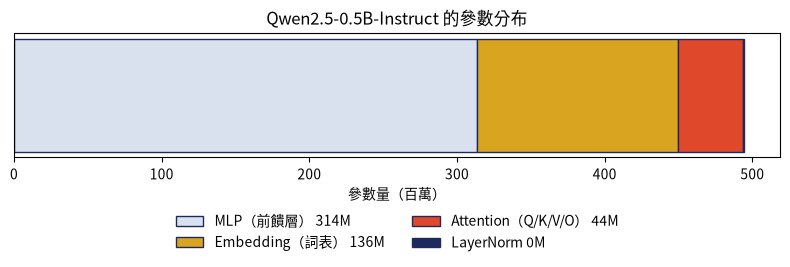

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.2))
left = 0
palette = {"Embedding（詞表）": "#d9a520", "Attention（Q/K/V/O）": "#e0482c", "MLP（前饋層）": "#d9e1ee", "LayerNorm": "#1f2a5c"}
for k, v in groups.most_common():
    ax.barh([0], [v / 1e6], left=left, color=palette[k], edgecolor="#1f2a5c", label=f"{k} {v / 1e6:.0f}M")
    left += v / 1e6
ax.set_yticks([])
ax.set_xlabel("參數量（百萬）")
ax.set_title("Qwen2.5-0.5B-Instruct 的參數分布")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

小模型有將近三成參數是詞表 embedding（15 萬個 token × 896 維）；到了 7B，這個比例會掉到一成以下，大部分參數在 MLP。
所以「多語言、大詞表」對小模型特別貴。

## Step 12：`safetensors`——權重檔的格式

早期的權重存成 `pytorch_model.bin`，那是 Python 的 pickle：**載入時可以執行任意程式碼**，下載來路不明的模型等於執行陌生人的程式。
`safetensors` 只存「名字、形狀、型別、位移」的索引和純數字，不能夾帶程式；而且可以只讀需要的那幾個矩陣（memory-map），載入更快。

In [16]:
from safetensors import safe_open

weights = hf_hub_download(MODEL, "model.safetensors")  # 已經在快取裡，不會重新下載
with safe_open(weights, framework="pt") as f:
    keys = list(f.keys())
    print("矩陣數：", len(keys), "｜檔頭中繼資料：", f.metadata())
    for k in keys[:4]:
        print(f"  {k:<45}{tuple(f.get_slice(k).get_shape())}")
    q = f.get_tensor("model.layers.0.self_attn.q_proj.weight")  # 只讀這一個矩陣
print("第 0 層 q_proj：", tuple(q.shape), q.dtype)

矩陣數： 290 ｜檔頭中繼資料： {'format': 'pt'}
  model.embed_tokens.weight                    (151936, 896)
  model.layers.0.input_layernorm.weight        (896,)
  model.layers.0.mlp.down_proj.weight          (896, 4864)
  model.layers.0.mlp.gate_proj.weight          (4864, 896)
第 0 層 q_proj： (896, 896) torch.bfloat16


## Step 13：`datasets`——載入、處理、切分資料集

資料集也在 Hub 上，用法跟模型一樣：給名字就下載、快取。`ag_news` 是四類新聞分類資料集。

In [17]:
from datasets import load_dataset

ds = load_dataset("fancyzhx/ag_news")
print(ds)
labels = ds["train"].features["label"].names
print("類別：", labels)
print("第一筆：", ds["train"][0]["text"][:100], "→", labels[ds["train"][0]["label"]])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
類別： ['World', 'Sports', 'Business', 'Sci/Tech']
第一筆： Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\b → Business


`map` 對每一筆做同一件事，`batched=True` 一次處理一批（快很多）。這裡加一欄「token 數」，再用 `filter` 和 `train_test_split`。
微調前的資料處理（模組 6）就是這個套路：載入 → `map` 轉成模型要的格式 → 切出驗證集。

In [18]:
small = ds["train"].shuffle(seed=0).select(range(2000))
small = small.map(lambda b: {"n_tokens": [len(x) for x in tok(b["text"]).input_ids]}, batched=True)
print(small)
print("平均 token 數：", sum(small["n_tokens"]) / len(small))

short = small.filter(lambda x: x["n_tokens"] <= 48)
split = short.train_test_split(test_size=0.2, seed=0)
print(f"≤48 token 的有 {len(short)} 筆 → 訓練 {len(split['train'])}、驗證 {len(split['test'])}")
print("類別分布：", Counter(labels[i] for i in split["train"]["label"]))

Dataset({
    features: ['text', 'label', 'n_tokens'],
    num_rows: 2000
})
平均 token 數： 52.5805
≤48 token 的有 909 筆 → 訓練 727、驗證 182
類別分布： Counter({'Sci/Tech': 217, 'Sports': 196, 'World': 172, 'Business': 142})


`datasets` 的資料存成 Arrow 格式放在磁碟上，不會整份塞進記憶體，所以幾 GB 的資料集也能這樣處理。

## Step 14：`peft` 和 `accelerate` 在哪裡

這兩個是「訓練」時才登場的配角，這裡只點一下：
- `accelerate`：幫你處理裝置。Step 9 的 `device_map="auto"` 就是它；多張 GPU、混合精度也靠它。
- `peft`：只訓練一小部分參數（例如 LoRA）。下面把 LoRA 掛到剛才的模型上，看要訓練的參數剩多少：

In [19]:
from peft import LoraConfig, get_peft_model

lora = get_peft_model(model, LoraConfig(r=8, target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM"))
lora.print_trainable_parameters()

trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093


只要訓練約 0.1% 的參數。怎麼訓練、為什麼這樣就夠，是模組 6 的內容。

## Step 15：HF 模型 vs Ollama，什麼時候用哪個

同樣是「在自己電腦跑開放模型」，兩條路的定位不同：

| | `transformers`（本本） | Ollama（Lab 1-04 起） |
|---|---|---|
| 權重格式 | safetensors，bf16／fp32 原始精度 | GGUF，通常 4-bit 量化 |
| 0.5B／3B 佔的空間 | 約 1GB／6GB | 約 0.4GB／1.9GB |
| 能看到什麼 | 每一層的 logits、attention、梯度 | 只有 API 回來的文字 |
| 能不能訓練 | 能（LoRA，模組 6） | 不能 |
| 用起來 | Python 裡直接呼叫 | 背景服務，OpenAI 相容 API，任何語言都能連 |
| 速度 | 沒量化、沒最佳化，較慢 | 為推論最佳化，CPU 也跑得動 |

經驗法則：**要看內部或要訓練 → `transformers`；要當服務給 agent 呼叫 → Ollama。**
模組 6 的流程正好串起兩者：用 `transformers` + `peft` 微調，合併後轉成 GGUF 交給 Ollama 服務。

## 試試看

1. 在 Step 4 加上 `Qwen/Qwen2.5-14B-Instruct` 和 `Qwen/Qwen2.5-32B-Instruct`，算出 bf16 權重要多少 GB，你的顯卡放得下哪一個？
2. 在 Step 10 把 `pipeline` 換成 `pipeline("sentiment-analysis")`（會下載一個小模型），丟三句英文影評看結果。
3. 在 Step 13 換成 `load_dataset("stanfordnlp/imdb")`，算平均 token 數，跟 ag_news 比差多少？這對微調時的 `max_length` 有什麼影響？

## 小結

- Hub 是放模型、資料集、Spaces 的平台；model card 寫授權和限制，gated 模型要同意授權加 `HF_TOKEN`。
- `huggingface_hub` 管下載與快取（`HF_HOME`、`scan_cache_dir`），`transformers` 用 tokenizer／model／`pipeline` 跑模型，`datasets` 載入與處理資料，`safetensors` 是安全的權重格式。
- 要看內部或訓練用 `transformers`，要當服務用 Ollama。下一本：用 `transformers` 打開 base model，看它怎麼猜下一個 token。